# ADS-505 Team 09 — Olist Customer Experience Risk: Seller-Level Model

**Team:** Asher Frank and Bereket Tarekegn  
**Course:** ADS-505 Applied Data Science for Business  
**Instructor:** Jules Malin, M.S.  
**Dataset:** Olist Brazilian E-Commerce Public Dataset

## Business problem
The team’s order-level analysis shows that delivery performance matters, but it does not fully explain customer experience. Many low reviews occur even among orders delivered on time. This seller-level model complements the order model by asking a longer-horizon management question.

## Seller-level business question
**Can Olist use only seller history available at a defined scoring date to identify sellers at elevated risk of generating a 1–2 star review in the next month?**

## Business action
- **Order model:** prioritize individual orders for operational monitoring.
- **Seller model:** prioritize historically active sellers for seller-management review and support.

The seller model uses historical-only eligibility, non-overlapping future outcome windows, a label-maturation gap, chronological validation, and an untouched final test period.

**Project contribution:** Seller-level customer-experience risk modeling to complement the team’s order-level early-warning model. This notebook reports historical predictive performance and interprets results for seller-management prioritization.


**Reproducibility:** Review selection is performed at order grain before seller attribution. Outputs were regenerated against the shared repository raw data after integration. The order-level and seller-level models are separate, complementary scoring tasks; their performance metrics are not directly comparable.


In [1]:
from IPython.display import display
# 1. Imports and reproducibility
from pathlib import Path
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
RANDOM_STATE = 42

## 2. Load all nine Olist tables
Use the repository's shared raw-data folder. Run this notebook from `02_notebooks`, after installing the imported Python packages.

In [2]:
required_files = {
    'customers': 'olist_customers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
}

DATA_DIR = Path('../01_data/raw')

print('Using data folder:', DATA_DIR.resolve())
data = {name: pd.read_csv(DATA_DIR / fname) for name, fname in required_files.items()}
for name, df in data.items():
    print(f'{name:22s}: {df.shape[0]:,} rows x {df.shape[1]} columns')

Using data folder: /Users/ajf311/Documents/GitHub/ADS-505/supply-chain-decision-support/01_data/raw


customers             : 99,441 rows x 5 columns


geolocation           : 1,000,163 rows x 5 columns


order_items           : 112,650 rows x 7 columns


payments              : 103,886 rows x 5 columns


reviews               : 99,224 rows x 7 columns


orders                : 99,441 rows x 8 columns


products              : 32,951 rows x 9 columns


sellers               : 3,095 rows x 4 columns


category_translation  : 71 rows x 2 columns


In [3]:
customers = data['customers'].copy()
geolocation = data['geolocation'].copy()
order_items = data['order_items'].copy()
payments = data['payments'].copy()
reviews = data['reviews'].copy()
orders = data['orders'].copy()
products = data['products'].copy()
sellers = data['sellers'].copy()
category_translation = data['category_translation'].copy()

for col in [
    'order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
    'order_delivered_customer_date','order_estimated_delivery_date'
]:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'], errors='coerce')
reviews['review_time'] = reviews['review_answer_timestamp'].fillna(reviews['review_creation_date'])
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'], errors='coerce')

# 3. Structural data-quality audit
Olist is relational. We audit missingness, duplicates, and order cardinality before creating analytical tables so raw many-to-many joins do not inflate totals.

In [4]:
inventory=[]
for name, df in data.items():
    inventory.append({
        'table':name,'rows':len(df),'columns':df.shape[1],
        'duplicate_rows':int(df.duplicated().sum()),
        'missing_cells':int(df.isna().sum().sum())
    })
inventory_df = pd.DataFrame(inventory).sort_values('rows', ascending=False)
display(inventory_df)

cardinality = pd.DataFrame({
    'table':['orders','order_items','payments','reviews'],
    'rows':[len(orders),len(order_items),len(payments),len(reviews)],
    'unique_orders':[orders.order_id.nunique(),order_items.order_id.nunique(),payments.order_id.nunique(),reviews.order_id.nunique()]
})
cardinality['rows_per_order'] = cardinality['rows']/cardinality['unique_orders']
display(cardinality)

,table,rows,columns,duplicate_rows,missing_cells
1,geolocation,1000163,5,261831,0
2,order_items,112650,7,0,0
3,payments,103886,5,0,0
0,customers,99441,5,0,0
5,orders,99441,8,0,4908
4,reviews,99224,7,0,145903
6,products,32951,9,0,2448
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0


,table,rows,unique_orders,rows_per_order
0,orders,99441,99441,1.000
1,order_items,112650,98666,1.142
2,payments,103886,99440,1.045
3,reviews,99224,98673,1.006


# 4. Multiple-review investigation
Repeated reviews are uncommon but can contain real score changes. Historical features use the latest review known by the scoring date. Future outcomes use the latest review available before the label-maturation deadline. A sensitivity analysis later compares latest, first, and mean strategies.

In [5]:
review_counts = reviews.groupby('order_id').size().rename('review_record_count')
multi_ids = review_counts[review_counts > 1].index
multi_reviews = reviews[reviews.order_id.isin(multi_ids)].sort_values(['order_id','review_time']).copy()
multi_profile = multi_reviews.groupby('order_id').agg(
    review_records=('review_id','size'), unique_scores=('review_score','nunique'),
    first_score=('review_score','first'), last_score=('review_score','last')
)
review_issue_summary = pd.Series({
    'reviewed_orders':reviews.order_id.nunique(),
    'orders_with_multiple_reviews':len(multi_profile),
    'percent_with_multiple_reviews':100*len(multi_profile)/reviews.order_id.nunique(),
    'multi_review_orders_with_score_change':int((multi_profile.unique_scores>1).sum())
})
review_issue_summary

reviewed_orders                         98,673.000
orders_with_multiple_reviews               547.000
percent_with_multiple_reviews                0.554
multi_review_orders_with_score_change      202.000
dtype: float64

# 5. Compact operational EDA
This verifies the team’s core narrative: lateness is related to low reviews, but low customer satisfaction is not identical to late delivery.

In [6]:
latest_review_per_order = (
    reviews.sort_values(['order_id','review_time'])
    .groupby('order_id', as_index=False).tail(1)[['order_id','review_score']]
    .rename(columns={'review_score':'latest_review_score'})
)
order_eda = orders.merge(latest_review_per_order, on='order_id', how='left')
order_eda['delay_days'] = (order_eda.order_delivered_customer_date-order_eda.order_estimated_delivery_date).dt.total_seconds()/86400
order_eda['late_delivery'] = np.where(order_eda.order_delivered_customer_date.notna(), order_eda.delay_days>0, np.nan)
order_eda['low_review'] = np.where(order_eda.latest_review_score.notna(), order_eda.latest_review_score<=2, np.nan)

delivery_review_summary = (
    order_eda.dropna(subset=['late_delivery','latest_review_score'])
    .groupby('late_delivery').agg(
        orders=('order_id','nunique'), average_review=('latest_review_score','mean'), low_review_rate=('low_review','mean')
    )
)
display(delivery_review_summary)

low_review_orders = order_eda[order_eda.low_review==1]
share_timely = (low_review_orders.late_delivery==0).mean()
print('Share of observed low-review orders delivered on/before promise:', f'{share_timely:.1%}')

,orders,average_review,low_review_rate
late_delivery,,,
0.000,88168,4.294,0.092
1.000,7662,2.565,0.541


Share of observed low-review orders delivered on/before promise: 56.1%


# 6. Build one seller-order table
Each row below represents one seller within one order. This avoids duplicating seller totals while retaining product, freight, delivery, and shipping-deadline information.

In [7]:
items_enriched = order_items.merge(
    products[['product_id','product_category_name']], on='product_id', how='left'
)
seller_order = (
    items_enriched.groupby(['order_id','seller_id'], as_index=False)
    .agg(
        item_lines=('order_item_id','count'), sales=('price','sum'), freight=('freight_value','sum'),
        unique_products=('product_id','nunique'), unique_categories=('product_category_name','nunique'),
        last_shipping_limit=('shipping_limit_date','max')
    )
    .merge(orders[[
        'order_id','order_purchase_timestamp','order_delivered_carrier_date',
        'order_delivered_customer_date','order_estimated_delivery_date','order_status'
    ]], on='order_id', how='left')
)
seller_first_purchase = seller_order.groupby('seller_id').order_purchase_timestamp.min()
seller_order.head()

,order_id,seller_id,item_lines,sales,freight,unique_products,unique_categories,last_shipping_limit,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,1,58.900,13.290,1,1,2017-09-19 09:45:35,2017-09-13 08:59:02,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,delivered
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,1,239.900,19.930,1,1,2017-05-03 11:05:13,2017-04-26 10:53:06,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,delivered
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,1,199.000,17.870,1,1,2018-01-18 14:48:30,2018-01-14 14:33:31,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,delivered
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,1,12.990,12.790,1,1,2018-08-15 10:10:18,2018-08-08 10:00:35,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,1,199.900,18.140,1,1,2017-02-13 13:57:51,2017-02-04 13:57:51,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,delivered


# 7. Leakage-safe seller snapshots with label maturation

**Unit:** one historically eligible seller at one scoring date.  
**Eligibility:** at least 5 orders in the prior 180 days, using historical information only.  
**Outcome window:** the next calendar month.  
**Maturation window:** one additional month for reviews to arrive before the next scoring date.  
**Target:** 1 if the seller generates at least one observed 1–2 star review in the next-month order cohort; otherwise 0.

Scoring dates are two months apart. Therefore future order windows do not overlap, and each snapshot’s labels are fully defined by the next scoring date.

In [8]:
def build_seller_cx_snapshot(cutoff, review_strategy='latest', history_days=180, min_history_orders=5):
    cutoff = pd.Timestamp(cutoff)
    outcome_end = cutoff + pd.offsets.MonthBegin(1)      # next-month order window ends
    label_deadline = cutoff + pd.DateOffset(months=2)    # reviews must be observable by next score date
    history_start = cutoff - pd.Timedelta(days=history_days)

    hist = seller_order[(seller_order.order_purchase_timestamp>=history_start) & (seller_order.order_purchase_timestamp<cutoff)].copy()
    hist['known_delivery'] = hist.order_delivered_customer_date.notna() & (hist.order_delivered_customer_date<cutoff)
    hist['late_known'] = np.where(hist.known_delivery, hist.order_delivered_customer_date>hist.order_estimated_delivery_date, np.nan)
    hist['delivery_days_known'] = np.where(
        hist.known_delivery,
        (hist.order_delivered_customer_date-hist.order_purchase_timestamp).dt.total_seconds()/86400,
        np.nan
    )
    hist['known_handoff'] = hist.order_delivered_carrier_date.notna() & (hist.order_delivered_carrier_date<cutoff)
    hist['deadline_miss_known'] = np.where(
        hist.known_handoff & hist.last_shipping_limit.notna(),
        hist.order_delivered_carrier_date>hist.last_shipping_limit, np.nan
    )

    hist_agg = hist.groupby('seller_id', as_index=False).agg(
        hist_orders=('order_id','nunique'), hist_sales=('sales','sum'), hist_freight=('freight','sum'),
        hist_item_lines=('item_lines','sum'), hist_unique_products=('unique_products','sum'),
        hist_unique_categories=('unique_categories','sum'), hist_late_rate=('late_known','mean'),
        hist_avg_delivery_days=('delivery_days_known','mean'), hist_deadline_miss_rate=('deadline_miss_known','mean'),
        last_order_time=('order_purchase_timestamp','max')
    )
    hist_agg['hist_avg_order_value'] = hist_agg.hist_sales/hist_agg.hist_orders
    hist_agg['hist_freight_ratio'] = hist_agg.hist_freight/(hist_agg.hist_sales+hist_agg.hist_freight).replace(0,np.nan)
    hist_agg['hist_items_per_order'] = hist_agg.hist_item_lines/hist_agg.hist_orders
    hist_agg['hist_products_per_order'] = hist_agg.hist_unique_products/hist_agg.hist_orders
    hist_agg['hist_categories_per_order'] = hist_agg.hist_unique_categories/hist_agg.hist_orders
    hist_agg['seller_recency_days'] = (cutoff-hist_agg.last_order_time).dt.total_seconds()/86400
    hist_agg['seller_tenure_days'] = hist_agg.seller_id.map(seller_first_purchase)
    hist_agg['seller_tenure_days'] = (cutoff-hist_agg.seller_tenure_days).dt.total_seconds()/86400

    # Resolve review outcome at ORDER grain before attributing it to each seller.
    # This preserves every seller on multi-seller orders, without counting repeated
    # review records as separate orders.
    hist_orders = hist[['order_id', 'seller_id']].drop_duplicates()
    eligible_hist_reviews = reviews.loc[reviews.review_time < cutoff].copy()
    if review_strategy == 'latest':
        order_hist_review = (eligible_hist_reviews.sort_values(['order_id', 'review_time'])
                             .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
    elif review_strategy == 'first':
        order_hist_review = (eligible_hist_reviews.sort_values(['order_id', 'review_time'])
                             .drop_duplicates('order_id', keep='first')[['order_id', 'review_score']])
    elif review_strategy == 'mean':
        order_hist_review = eligible_hist_reviews.groupby('order_id', as_index=False)['review_score'].mean()
    else:
        raise ValueError('review_strategy must be latest, first, or mean')
    hist_review_order = hist_orders.merge(order_hist_review, on='order_id', how='inner')

    if len(hist_review_order):
        hist_review_order['hist_low_review']=(hist_review_order.review_score<=2).astype(int)
        hist_review_agg=hist_review_order.groupby('seller_id',as_index=False).agg(
            hist_avg_review=('review_score','mean'), hist_low_review_rate=('hist_low_review','mean'), hist_reviewed_orders=('order_id','nunique')
        )
    else:
        hist_review_agg=pd.DataFrame(columns=['seller_id','hist_avg_review','hist_low_review_rate','hist_reviewed_orders'])
    hist_agg=hist_agg.merge(hist_review_agg,on='seller_id',how='left')

    snapshot=hist_agg[hist_agg.hist_orders>=min_history_orders].copy()  # historical-only eligibility

    future_orders = seller_order[
        (seller_order.order_purchase_timestamp>=cutoff) & (seller_order.order_purchase_timestamp<outcome_end)
    ][['order_id','seller_id']].drop_duplicates()
    # Review records are selected once per order, then associated with ALL sellers
    # on that order. This is order-level attribution, not proof of seller causation.
    eligible_future_reviews = reviews.loc[reviews.review_time < label_deadline].copy()
    if review_strategy == 'latest':
        order_future_review = (eligible_future_reviews.sort_values(['order_id', 'review_time'])
                               .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
    elif review_strategy == 'first':
        order_future_review = (eligible_future_reviews.sort_values(['order_id', 'review_time'])
                               .drop_duplicates('order_id', keep='first')[['order_id', 'review_score']])
    elif review_strategy == 'mean':
        order_future_review = eligible_future_reviews.groupby('order_id', as_index=False)['review_score'].mean()
    else:
        raise ValueError('review_strategy must be latest, first, or mean')
    future_review_order = future_orders.merge(order_future_review, on='order_id', how='inner')

    if len(future_review_order):
        future_review_order['future_low_review']=(future_review_order.review_score<=2).astype(int)
        future_outcome=future_review_order.groupby('seller_id',as_index=False).agg(
            future_reviewed_orders=('order_id','nunique'), future_low_review_events=('future_low_review','sum'), future_avg_review=('review_score','mean')
        )
    else:
        future_outcome=pd.DataFrame(columns=['seller_id','future_reviewed_orders','future_low_review_events','future_avg_review'])

    snapshot=snapshot.merge(future_outcome,on='seller_id',how='left')
    snapshot['future_reviewed_orders']=snapshot.future_reviewed_orders.fillna(0)
    snapshot['future_low_review_events']=snapshot.future_low_review_events.fillna(0)
    snapshot['target']=(snapshot.future_low_review_events>=1).astype(int)
    snapshot['cutoff']=cutoff
    snapshot['outcome_end']=outcome_end
    snapshot['label_deadline']=label_deadline
    snapshot['review_strategy']=review_strategy
    return snapshot

# 8. Build non-overlapping scoring snapshots
The six scoring dates are two months apart. Train, validation, and test periods are chronological.

,seller_snapshots,positive_rate,avg_future_reviewed_orders
cutoff,,,
2017-07-01,472,0.324,7.133
2017-09-01,580,0.291,6.202
2017-11-01,650,0.443,9.349
2018-01-01,791,0.382,7.630
2018-03-01,921,0.457,6.988
2018-05-01,1030,0.275,5.834


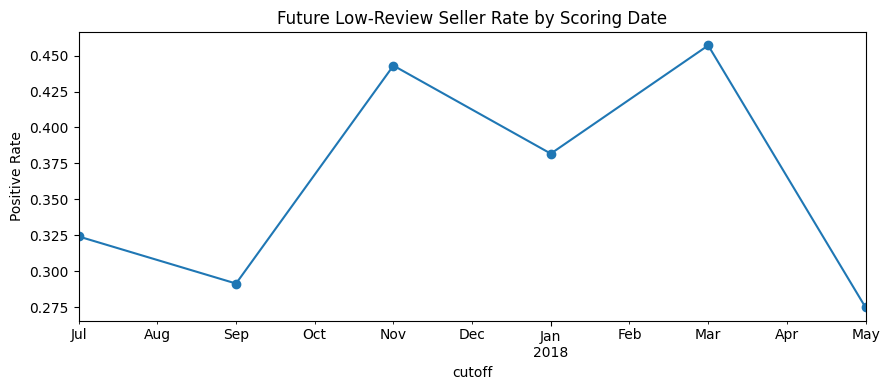

In [9]:
snapshot_dates = pd.to_datetime([
    '2017-07-01','2017-09-01','2017-11-01',
    '2018-01-01','2018-03-01','2018-05-01'
])
model_data = pd.concat([build_seller_cx_snapshot(d,'latest') for d in snapshot_dates], ignore_index=True)
snapshot_summary = model_data.groupby('cutoff').agg(
    seller_snapshots=('seller_id','size'), positive_rate=('target','mean'),
    avg_future_reviewed_orders=('future_reviewed_orders','mean')
)
display(snapshot_summary)
plt.figure(figsize=(9,4)); snapshot_summary.positive_rate.plot(marker='o');
plt.title('Future Low-Review Seller Rate by Scoring Date'); plt.ylabel('Positive Rate'); plt.tight_layout(); plt.show()

# 9. Predictor set
All predictors are historical and available before the scoring date.

In [10]:
features = [
    'hist_orders','hist_sales','hist_freight','hist_item_lines','hist_unique_products','hist_unique_categories',
    'hist_late_rate','hist_avg_delivery_days','hist_deadline_miss_rate','hist_avg_order_value','hist_freight_ratio',
    'hist_items_per_order','hist_products_per_order','hist_categories_per_order','seller_recency_days','seller_tenure_days',
    'hist_avg_review','hist_low_review_rate','hist_reviewed_orders'
]
feature_dictionary = pd.DataFrame([
    ['hist_orders','Historical order count'],['hist_sales','Historical merchandise sales'],
    ['hist_freight','Historical freight value'],['hist_item_lines','Historical item-line volume'],
    ['hist_unique_products','Historical product breadth'],['hist_unique_categories','Historical category breadth'],
    ['hist_late_rate','Known historical late-delivery rate'],['hist_avg_delivery_days','Average known historical delivery time'],
    ['hist_deadline_miss_rate','Known seller shipping-deadline miss rate'],['hist_avg_order_value','Historical average order value'],
    ['hist_freight_ratio','Freight share of merchandise + freight'],['hist_items_per_order','Historical item lines per order'],
    ['hist_products_per_order','Historical products per order'],['hist_categories_per_order','Historical categories per order'],
    ['seller_recency_days','Days since most recent order'],['seller_tenure_days','Days since first observed seller order'],
    ['hist_avg_review','Average historical review known by cutoff'],['hist_low_review_rate','Historical 1–2 star review rate'],
    ['hist_reviewed_orders','Historical reviewed-order count']
], columns=['feature','business_meaning'])
feature_dictionary

,feature,business_meaning
0,hist_orders,Historical order count
1,hist_sales,Historical merchandise sales
2,hist_freight,Historical freight value
3,hist_item_lines,Historical item-line volume
4,hist_unique_products,Historical product breadth
5,hist_unique_categories,Historical category breadth
6,hist_late_rate,Known historical late-delivery rate
7,hist_avg_delivery_days,Average known historical delivery time
8,hist_deadline_miss_rate,Known seller shipping-deadline miss rate
9,hist_avg_order_value,Historical average order value


# 10. Missing values, outliers, correlation, and association analysis
Missing numeric values are median-imputed inside each pipeline. Legitimate business outliers are retained. Correlated predictors are documented rather than automatically removed because the final tree-based model can tolerate redundancy.

In [11]:
missing_audit = pd.DataFrame({'missing_count':model_data[features].isna().sum(),'missing_rate':model_data[features].isna().mean()}).sort_values('missing_rate',ascending=False)
display(missing_audit)

outlier_rows=[]
for col in features:
    s=model_data[col].dropna(); q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    outlier_rows.append({'feature':col,'outlier_count_iqr':int(((s<lower)|(s>upper)).sum()),'outlier_rate_iqr':((s<lower)|(s>upper)).mean()})
outlier_audit=pd.DataFrame(outlier_rows).sort_values('outlier_rate_iqr',ascending=False)
display(outlier_audit.head(10))

corr=model_data[features].corr(numeric_only=True)
high=[]
for i,c1 in enumerate(corr.columns):
    for c2 in corr.columns[i+1:]:
        v=corr.loc[c1,c2]
        if pd.notna(v) and abs(v)>=.80: high.append({'feature_1':c1,'feature_2':c2,'correlation':v})
high_corr_df=pd.DataFrame(high)
display(high_corr_df)

association = model_data[features+['target']].corr(numeric_only=True)['target'].drop('target').sort_values(key=lambda s:s.abs(),ascending=False).to_frame('correlation_with_target')
display(association)

,missing_count,missing_rate
hist_late_rate,10,0.002
hist_avg_delivery_days,10,0.002
hist_reviewed_orders,8,0.002
hist_low_review_rate,8,0.002
hist_avg_review,8,0.002
hist_deadline_miss_rate,5,0.001
hist_items_per_order,0,0.000
seller_tenure_days,0,0.000
seller_recency_days,0,0.000
hist_categories_per_order,0,0.000


,feature,outlier_count_iqr,outlier_rate_iqr
12,hist_products_per_order,933,0.210
13,hist_categories_per_order,547,0.123
0,hist_orders,465,0.105
4,hist_unique_products,463,0.104
5,hist_unique_categories,460,0.104
1,hist_sales,458,0.103
18,hist_reviewed_orders,449,0.101
3,hist_item_lines,444,0.100
2,hist_freight,437,0.098
14,seller_recency_days,435,0.098


,feature_1,feature_2,correlation
0,hist_orders,hist_freight,0.914
1,hist_orders,hist_item_lines,0.992
2,hist_orders,hist_unique_products,0.999
3,hist_orders,hist_unique_categories,0.996
4,hist_orders,hist_reviewed_orders,0.998
5,hist_freight,hist_item_lines,0.933
6,hist_freight,hist_unique_products,0.914
7,hist_freight,hist_unique_categories,0.913
8,hist_freight,hist_reviewed_orders,0.908
9,hist_item_lines,hist_unique_products,0.993


,correlation_with_target
hist_orders,0.306
hist_unique_products,0.305
hist_unique_categories,0.304
hist_item_lines,0.304
seller_recency_days,-0.301
hist_reviewed_orders,0.296
hist_freight,0.292
hist_sales,0.244
hist_categories_per_order,0.086
hist_avg_order_value,-0.056


# 11. Chronological train / validation / test design
- **Train:** July, September, November 2017 snapshots  
- **Validation:** January and March 2018 snapshots  
- **Test:** May 2018 snapshot

The May test snapshot is untouched during model selection and tuning.

In [12]:
train=model_data[model_data.cutoff.isin(pd.to_datetime(['2017-07-01','2017-09-01','2017-11-01']))].copy()
validation=model_data[model_data.cutoff.isin(pd.to_datetime(['2018-01-01','2018-03-01']))].copy()
test=model_data[model_data.cutoff.eq(pd.Timestamp('2018-05-01'))].copy()
split_summary=pd.DataFrame({
    'split':['Train','Validation','Test'],'rows':[len(train),len(validation),len(test)],
    'positive_rate':[train.target.mean(),validation.target.mean(),test.target.mean()],
    'first_cutoff':[train.cutoff.min(),validation.cutoff.min(),test.cutoff.min()],
    'last_cutoff':[train.cutoff.max(),validation.cutoff.max(),test.cutoff.max()]
})
split_summary

,split,rows,positive_rate,first_cutoff,last_cutoff
0,Train,1702,0.358,2017-07-01,2017-11-01
1,Validation,1712,0.422,2018-01-01,2018-03-01
2,Test,1030,0.275,2018-05-01,2018-05-01


# 12. Baseline and candidate models
A majority-class baseline can look accurate while identifying no positive sellers. The business use is ranking, so PR-AUC, ROC-AUC, lift, and capture are central.

In [13]:
baseline_accuracy=max(validation.target.mean(),1-validation.target.mean())
display(pd.DataFrame({'baseline':['Predict majority class'],'validation_accuracy':[baseline_accuracy],'positive_recall':[0.0]}))

target='target'
scaled=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
treeprep=Pipeline([('imputer',SimpleImputer(strategy='median'))])
models={
    'Logistic Regression':Pipeline([('prep',scaled),('model',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))]),
    'Decision Tree':Pipeline([('prep',treeprep),('model',DecisionTreeClassifier(max_depth=6,min_samples_leaf=20,class_weight='balanced',random_state=RANDOM_STATE))]),
    'Random Forest':Pipeline([('prep',treeprep),('model',RandomForestClassifier(n_estimators=120,max_depth=10,min_samples_leaf=8,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
}

,baseline,validation_accuracy,positive_recall
0,Predict majority class,0.578,0.000


In [14]:
def top_fraction_metrics(y_true, probability, fraction=.10):
    frame=pd.DataFrame({'actual':np.asarray(y_true),'probability':np.asarray(probability)}).sort_values('probability',ascending=False)
    n=max(1,int(np.ceil(len(frame)*fraction))); selected=frame.head(n); base=frame.actual.mean()
    precision_sel=selected.actual.mean(); capture=selected.actual.sum()/frame.actual.sum() if frame.actual.sum()>0 else np.nan
    lift=precision_sel/base if base>0 else np.nan
    return precision_sel,capture,lift

def metric_row(name,y_true,probability,seconds=np.nan,threshold=.50):
    pred=(np.asarray(probability)>=threshold).astype(int); p10,c10,l10=top_fraction_metrics(y_true,probability,.10)
    return {'model':name,'seconds':seconds,'accuracy':accuracy_score(y_true,pred),'precision':precision_score(y_true,pred,zero_division=0),
            'recall':recall_score(y_true,pred,zero_division=0),'f1':f1_score(y_true,pred,zero_division=0),
            'roc_auc':roc_auc_score(y_true,probability),'pr_auc':average_precision_score(y_true,probability),
            'top10_precision':p10,'top10_capture':c10,'top10_lift':l10}

validation_probabilities={}; fitted_models={}; rows=[]
for name,model in models.items():
    print('Training',name,'...'); t0=perf_counter(); model.fit(train[features],train[target]); prob=model.predict_proba(validation[features])[:,1]; elapsed=perf_counter()-t0
    fitted_models[name]=model; validation_probabilities[name]=prob; rows.append(metric_row(name,validation[target],prob,elapsed)); print(f'Finished in {elapsed:.2f}s')
validation_results=pd.DataFrame(rows).sort_values(['top10_lift','pr_auc'],ascending=False).reset_index(drop=True)
validation_results

Training Logistic Regression ...


Finished in 0.01s


Training Decision Tree ...


Finished in 0.01s


Training Random Forest ...


Finished in 0.16s


,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift
0,Random Forest,0.160,0.707,0.692,0.552,0.614,0.754,0.705,0.866,0.206,2.051
1,Logistic Regression,0.008,0.693,0.649,0.593,0.620,0.753,0.706,0.855,0.203,2.024
2,Decision Tree,0.009,0.691,0.667,0.537,0.595,0.730,0.667,0.837,0.199,1.982


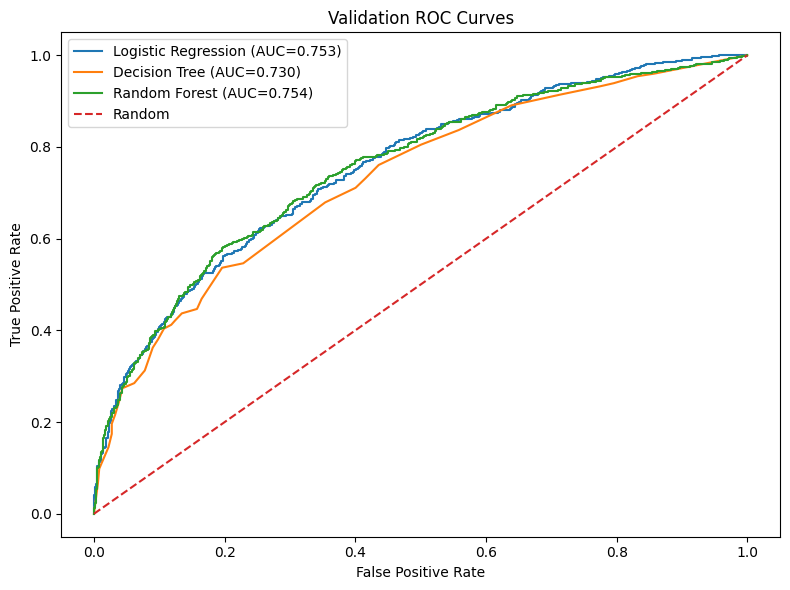

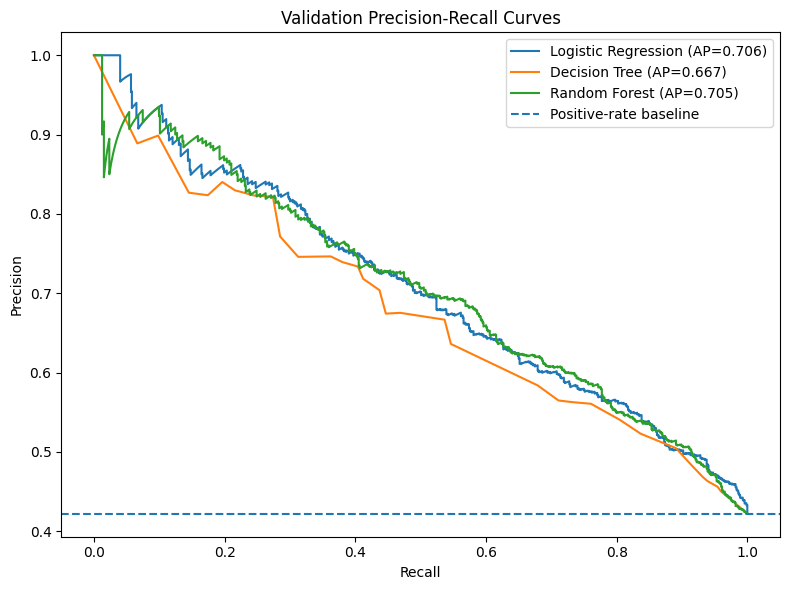

In [15]:
plt.figure(figsize=(8,6))
for name,prob in validation_probabilities.items():
    fpr,tpr,_=roc_curve(validation[target],prob); plt.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(validation[target],prob):.3f})')
plt.plot([0,1],[0,1],linestyle='--',label='Random'); plt.title('Validation ROC Curves'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,6))
for name,prob in validation_probabilities.items():
    precision_curve,recall_curve,_=precision_recall_curve(validation[target],prob); plt.plot(recall_curve,precision_curve,label=f'{name} (AP={average_precision_score(validation[target],prob):.3f})')
plt.axhline(validation[target].mean(),linestyle='--',label='Positive-rate baseline'); plt.title('Validation Precision-Recall Curves'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.tight_layout(); plt.show()

# 13. Capacity analysis and tuning
The seller-success team may only have capacity to review a fraction of sellers. We evaluate top 10%, 20%, and 30% ranking scenarios and use top-decile lift as the primary selection metric because seller-success capacity is limited; PR-AUC is the secondary ranking metric. Random Forest is tuned only if it leads under this rule.

In [16]:
def capacity_metrics(y_true,probability,fractions=(.10,.20,.30)):
    frame=pd.DataFrame({'actual':np.asarray(y_true),'probability':np.asarray(probability)}).sort_values('probability',ascending=False)
    total=frame.actual.sum(); base=frame.actual.mean(); rows=[]
    for frac in fractions:
        n=max(1,int(np.ceil(len(frame)*frac))); sel=frame.head(n); precision_sel=sel.actual.mean(); capture=sel.actual.sum()/total if total>0 else np.nan; lift=precision_sel/base if base>0 else np.nan
        rows.append({'capacity':f'Top {int(frac*100)}%','selected_sellers':n,'precision_selected':precision_sel,'capture_of_all_positives':capture,'lift':lift})
    return pd.DataFrame(rows)

caps=[]
for name,prob in validation_probabilities.items():
    t=capacity_metrics(validation[target],prob); t.insert(0,'model',name); caps.append(t)
validation_capacity=pd.concat(caps,ignore_index=True); display(validation_capacity)

leading_model_name=validation_results.iloc[0].model; print('Leading validation model:',leading_model_name)
if leading_model_name=='Random Forest':
    candidates=[
        {'n_estimators':100,'max_depth':8,'min_samples_leaf':10,'max_features':'sqrt'},
        {'n_estimators':150,'max_depth':12,'min_samples_leaf':8,'max_features':'sqrt'},
        {'n_estimators':200,'max_depth':16,'min_samples_leaf':6,'max_features':'sqrt'}]
    tuning_rows=[]; tuned=[]
    for i,p in enumerate(candidates,1):
        m=Pipeline([('prep',SimpleImputer(strategy='median')),('model',RandomForestClassifier(**p,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
        m.fit(train[features],train[target]); prob=m.predict_proba(validation[features])[:,1]; row=metric_row(f'RF Candidate {i}',validation[target],prob); row.update(p); tuning_rows.append(row); tuned.append(m)
    rf_tuning_results=pd.DataFrame(tuning_rows).sort_values(['top10_lift','pr_auc'],ascending=False).reset_index(); display(rf_tuning_results)
    best_model=tuned[int(rf_tuning_results.loc[0,'index'])]
else:
    best_model=fitted_models[leading_model_name]
best_validation_probability=best_model.predict_proba(validation[features])[:,1]
print('Selected validation ROC-AUC:',round(roc_auc_score(validation[target],best_validation_probability),3))
print('Selected validation PR-AUC:',round(average_precision_score(validation[target],best_validation_probability),3))

,model,capacity,selected_sellers,precision_selected,capture_of_all_positives,lift
0,Logistic Regression,Top 10%,172,0.855,0.203,2.024
1,Logistic Regression,Top 20%,343,0.767,0.364,1.816
2,Logistic Regression,Top 30%,514,0.702,0.499,1.663
3,Decision Tree,Top 10%,172,0.837,0.199,1.982
4,Decision Tree,Top 20%,343,0.752,0.357,1.781
5,Decision Tree,Top 30%,514,0.669,0.476,1.585
6,Random Forest,Top 10%,172,0.866,0.206,2.051
7,Random Forest,Top 20%,343,0.758,0.360,1.795
8,Random Forest,Top 30%,514,0.706,0.502,1.672


Leading validation model: Random Forest


,index,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift,n_estimators,max_depth,min_samples_leaf,max_features
0,0,RF Candidate 1,NaN,0.701,0.683,0.545,0.606,0.755,0.706,0.866,0.206,2.051,100,8,10,sqrt
1,2,RF Candidate 3,NaN,0.703,0.690,0.539,0.606,0.751,0.704,0.866,0.206,2.051,200,16,6,sqrt
2,1,RF Candidate 2,NaN,0.705,0.686,0.556,0.614,0.753,0.707,0.860,0.205,2.038,150,12,8,sqrt


Selected validation ROC-AUC: 0.755


Selected validation PR-AUC: 0.706


# 14. Final fit and untouched test evaluation
After model selection using train/validation only, refit on train + validation and evaluate once on the May 2018 test snapshot.

,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift
0,Final Seller CX Risk Model,NaN,0.713,0.484,0.693,0.570,0.791,0.625,0.738,0.269,2.686


              precision    recall  f1-score   support

           0      0.861     0.720     0.784       747
           1      0.484     0.693     0.570       283

    accuracy                          0.713      1030
   macro avg      0.672     0.706     0.677      1030
weighted avg      0.757     0.713     0.725      1030



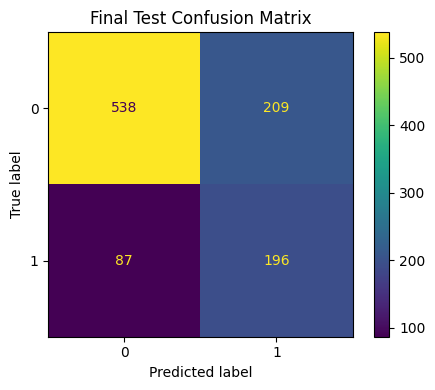

,capacity,selected_sellers,precision_selected,capture_of_all_positives,lift
0,Top 10%,103,0.738,0.269,2.686
1,Top 20%,206,0.592,0.431,2.155
2,Top 30%,309,0.528,0.576,1.920


In [17]:
train_validation=pd.concat([train,validation],ignore_index=True)
final_model=clone(best_model); final_model.fit(train_validation[features],train_validation[target])
test_probability=final_model.predict_proba(test[features])[:,1]
test_metrics=metric_row('Final Seller CX Risk Model',test[target],test_probability)
display(pd.DataFrame([test_metrics]))

test_prediction=(test_probability>=.50).astype(int)
print(classification_report(test[target],test_prediction,digits=3))
fig,ax=plt.subplots(figsize=(5,4)); ConfusionMatrixDisplay.from_predictions(test[target],test_prediction,ax=ax); plt.title('Final Test Confusion Matrix'); plt.tight_layout(); plt.show()

test_capacity=capacity_metrics(test[target],test_probability); display(test_capacity)

# 15. Feature importance
Feature importance describes what the Random Forest uses for ranking; it does not prove causality.

,feature,importance
0,seller_recency_days,0.156
1,hist_item_lines,0.101
2,hist_orders,0.100
3,hist_unique_products,0.092
4,hist_freight,0.087
5,hist_unique_categories,0.085
6,seller_tenure_days,0.064
7,hist_reviewed_orders,0.054
8,hist_sales,0.037
9,hist_avg_order_value,0.031


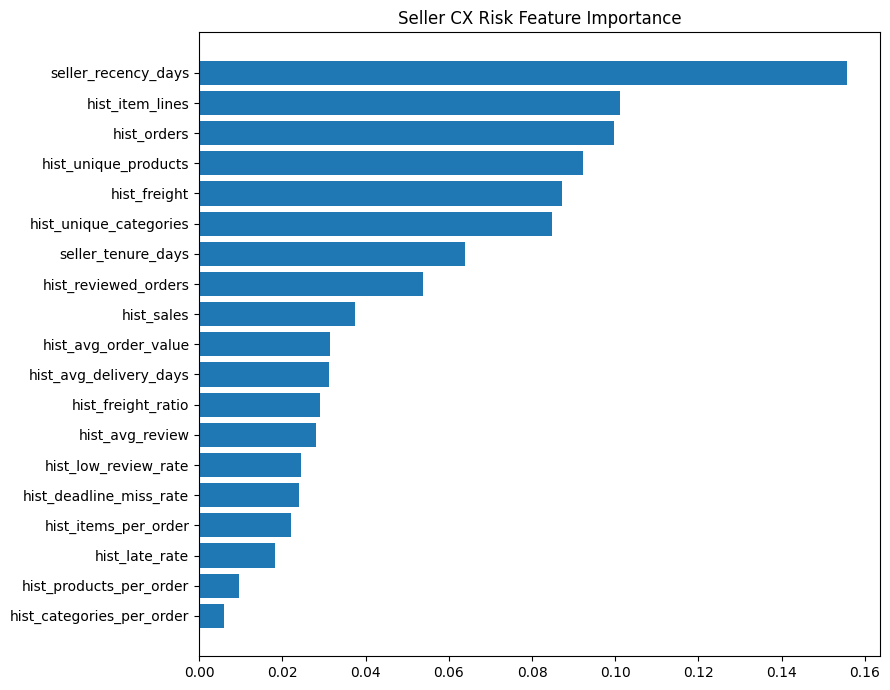

In [18]:
if hasattr(final_model.named_steps['model'],'feature_importances_'):
    importance=pd.DataFrame({'feature':features,'importance':final_model.named_steps['model'].feature_importances_}).sort_values('importance',ascending=False).reset_index(drop=True)
    display(importance)
    p=importance.sort_values('importance'); plt.figure(figsize=(9,7)); plt.barh(p.feature,p.importance); plt.title('Seller CX Risk Feature Importance'); plt.tight_layout(); plt.show()
else:
    print('Selected model does not expose tree feature importance.')

# 16. Review-definition sensitivity
Rebuild the seller snapshots using latest, mean, and first review definitions to test whether the rare multiple-review issue changes the conclusion.

In [19]:
sensitivity=[]
for strategy in ['latest','mean','first']:
    sd=pd.concat([build_seller_cx_snapshot(d,strategy) for d in snapshot_dates],ignore_index=True)
    st=sd[sd.cutoff.isin(pd.to_datetime(['2017-07-01','2017-09-01','2017-11-01','2018-01-01','2018-03-01']))].copy()
    ss=sd[sd.cutoff.eq(pd.Timestamp('2018-05-01'))].copy()
    sm=clone(final_model); sm.fit(st[features],st[target]); sp=sm.predict_proba(ss[features])[:,1]; top20=capacity_metrics(ss[target],sp,(.20,)).iloc[0]
    sensitivity.append({'review_strategy':strategy,'test_rows':len(ss),'positive_rate':ss[target].mean(),'roc_auc':roc_auc_score(ss[target],sp),'pr_auc':average_precision_score(ss[target],sp),'top20_precision':top20.precision_selected,'top20_capture':top20.capture_of_all_positives,'top20_lift':top20.lift})
review_sensitivity=pd.DataFrame(sensitivity); review_sensitivity

,review_strategy,test_rows,positive_rate,roc_auc,pr_auc,top20_precision,top20_capture,top20_lift
0,latest,1030,0.275,0.791,0.625,0.592,0.431,2.155
1,mean,1030,0.275,0.789,0.618,0.597,0.435,2.173
2,first,1030,0.276,0.786,0.617,0.558,0.405,2.025


# 17. Technical Model Brief

### What was tried
Logistic Regression, Decision Tree, and Random Forest were compared on chronological validation data. Model selection prioritizes top-decile lift because the business action is capacity-constrained seller review; PR-AUC is used as a secondary ranking metric. Random Forest is tuned if it leads under this rule.

### Why
The models provide an interpretable linear benchmark, a simple nonlinear benchmark, and an ensemble capable of interactions.

### What the model supports
The seller model estimates the probability that a historically active seller will generate at least one observed 1–2 star review in the next-month order cohort.

### How it complements the order model
- **Order model:** early warning for individual orders at placement time.
- **Seller model:** next-month customer-experience risk for seller management.

### Decision use
Use scores to rank sellers for review/support under limited capacity, not to automatically penalize or remove sellers.

### Final model selection
Random Forest was selected because the business use case focuses on prioritizing sellers with limited review capacity. On validation data, the tuned model achieved a top-decile lift of 2.05×, PR-AUC of 0.706, and ROC-AUC of 0.755. These results supported its selection for the final evaluation.

On the untouched May 2018 test snapshot, the final Random Forest achieved ROC-AUC of 0.791 and PR-AUC of 0.625. At a top-20% seller-review capacity, the selected group captured 43.1% of sellers with an observed future low-review event, representing a 2.16× lift over random selection.


In [20]:
test_auc=roc_auc_score(test[target],test_probability); test_ap=average_precision_score(test[target],test_probability); top20=test_capacity[test_capacity.capacity=='Top 20%'].iloc[0]
print('FINAL SELLER CX RISK SUMMARY'); print('-'*60)
print(f'Final test seller snapshots: {len(test):,}')
print(f'Final test positive rate: {test[target].mean():.1%}')
print(f'Final test ROC-AUC: {test_auc:.3f}')
print(f'Final test PR-AUC: {test_ap:.3f}')
print(f'Top 20% precision: {top20.precision_selected:.1%}')
print(f'Top 20% capture: {top20.capture_of_all_positives:.1%}')
print(f'Top 20% lift: {top20.lift:.2f}x')

FINAL SELLER CX RISK SUMMARY


------------------------------------------------------------


Final test seller snapshots: 1,030


Final test positive rate: 27.5%


Final test ROC-AUC: 0.791


Final test PR-AUC: 0.625


Top 20% precision: 59.2%


Top 20% capture: 43.1%


Top 20% lift: 2.16x


# 18. Limitations and next steps

1. Historical public data may not represent current marketplace conditions.
2. Reviews are observational and not every order receives a review; no observed low review does not guarantee satisfaction.
3. Feature importance is predictive, not causal.
4. Sellers can appear in multiple snapshots, although future outcome windows are non-overlapping and labels mature before the next scoring date.
5. Eligibility is historical-only; future order volume is never used to decide who gets scored.
6. The dataset omits inventory availability, staffing, support history, and intervention history.
7. True intervention costs are unavailable, so dollar ROI should not be invented.
8. A prospective pilot and drift monitoring would be required before deployment.

### Recommended next steps
- Use seller-risk ranking alongside the team’s order-level early-warning results for a coordinated customer-experience management view.
- Choose an operational review capacity such as top 20%.
- Track seller outreach, low-review incidence, and fulfillment outcomes prospectively.
- Add richer operational features if available.
- Finalize the technical notebook, business brief, and presentation around one customer-experience narrative.

8. **Multiple-seller order attribution:** A review belongs to the order. For multi-seller orders, the same order review is associated with each participating seller; it cannot identify which seller caused the outcome. Reviews are deduplicated at the order level before joining to sellers.
9. **Target exposure:** The target is at least one observed low-review event among the next month's orders, not a seller's underlying low-review rate. Higher-volume sellers have more opportunities for a positive event. Sellers without an observed low review (including sellers without reviewed future orders) receive a zero label; this is not proof of satisfaction.
10. **Review maturation:** The label deadline provides a consistent observation window, not a guarantee that all reviews have arrived.



# 19. Reproducibility and references

**GitHub repository:** https://github.com/asherdata1/supply-chain-decision-support

**Dataset citation (APA 7):**  
Olist. (2018). *Brazilian E-Commerce Public Dataset by Olist* [Data set]. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

The final team notebook should preserve visible GitHub commit history and document the Python environment/packages used for reproducibility.


# 20. Final project checklist
- [x] Business problem and stakeholder
- [x] Data description and structural audit
- [x] Decision-focused EDA
- [x] Missingness, outliers, and correlation review
- [x] Association analysis
- [x] Prediction point and leakage controls
- [x] Historical-only seller eligibility
- [x] Non-overlapping future outcome windows
- [x] Label-maturation deadline
- [x] Chronological train/validation/test design
- [x] Naive baseline
- [x] Multiple-model comparison
- [x] Validation-only tuning
- [x] Untouched final test
- [x] ROC-AUC, PR-AUC, precision, recall, F1
- [x] Lift/capture capacity analysis
- [x] Feature importance
- [x] Review-definition sensitivity
- [x] Technical Model Brief
- [x] Limitations and next steps
- [x] Add final GitHub repository link
- [x] Add APA dataset citation
- [ ] Consolidate with the order-level notebook
- [ ] Export final notebook PDF